# Bayesian Classifiers & Generative Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/konstantin-schekotihin/dl_course/blob/master/AI-ML/aux1_BN.ipynb)


In [1]:
# Setup & configuration (skip in presentation slides)
%matplotlib inline
from IPython.display import Markdown, display
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
import sklearn.metrics as mt

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import aiml as hp
hp.setup_theme()

## 1. Probabilistic Foundations & Bayes' Theorem

### Two Roles for Bayesian Methods in Machine Learning

- Provides practical learning algorithms:
    + Naive Bayes (this lecture)
    + further ones not covered here, e.g. Bayesian belief networks and linear discriminant analysis
- Combine prior knowledge (prior probabilities) with observed data
    + Requires prior probabilities
- Provides useful conceptual framework
    + Provides an unattainable "gold standard" for evaluating other learning algorithms (the Bayes classifier, §3)

<small>📖 *Source: [Mitchell, T. M. (1997). Machine Learning. McGraw-Hill](https://www.cs.cmu.edu/~tom/mlbook.html)*</small>

### Bayes' Theorem for Hypotheses

- Given observed dataset $\mathcal{D}$ and candidate hypotheses $\mathcal{H} = \{h_1, \dots, h_M\}$:
- The **posterior probability** of hypothesis $h$ given data $\mathcal{D}$ is:

$$
p(h \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid h) p(h)}{p(\mathcal{D})}
$$

- **Components of Bayesian Inference**:
  - **Prior $p(h)$**: Initial belief in hypothesis $h$ before observing data.
  - **Likelihood $p(\mathcal{D} \mid h)$**: Probability of observing data $\mathcal{D}$ under hypothesis $h$.
  - **Marginal Evidence $p(\mathcal{D})$**: Normalization factor $p(\mathcal{D}) = \sum_{h' \in \mathcal{H}} p(\mathcal{D} \mid h') p(h')$.
  - **Posterior $p(h \mid \mathcal{D})$**: Updated belief in hypothesis $h$ after observing $\mathcal{D}$.

### Diagnostic Dilemma: Medical Screening Benchmark

> 📘 **Case Study: Diagnostic Testing**
>
> A patient tests positive ($+$) on a diagnostic screening test. The test has:
> - **Sensitivity** (True Positive Rate): $98\%$
> - **False Positive Rate**: $3\%$
> - **Disease Prevalence** in population: $0.8\%$
>
> **Question:** What is the posterior probability that the patient actually has the disease?


### Resolving the Screening Dilemma via Posterior Probabilities

- Prior probabilities and test characteristics:

$$
\begin{aligned}
p(\text{disease}) &= 0.008, & p(\neg \text{disease}) &= 0.992 \\
p(+ \mid \text{disease}) &= 0.98, & p(- \mid \text{disease}) &= 0.02 \\
p(+ \mid \neg \text{disease}) &= 0.03, & p(- \mid \neg \text{disease}) &= 0.97
\end{aligned}
$$

- Evaluating unnormalized posterior likelihoods:

$$
\begin{aligned}
p(\text{disease} \mid +) &\propto p(+ \mid \text{disease}) p(\text{disease}) = 0.98 \times 0.008 = 0.00784 \\
p(\neg \text{disease} \mid +) &\propto p(+ \mid \neg \text{disease}) p(\neg \text{disease}) = 0.03 \times 0.992 = 0.02976
\end{aligned}
$$

- Normalizing: $p(\text{disease} \mid +) = \frac{0.00784}{0.00784 + 0.02976} \approx 20.85\%$.

> 💡 **Key Takeaway:** Even with $98\%$ test sensitivity, when the prior prevalence is low ($0.8\%$), a positive test result only yields a $\approx 21\%$ probability of actual disease.


In [2]:
# The screening example, computed: prior, likelihood of a positive test, posterior
prior = np.array([0.008, 0.992])                 # p(disease), p(no disease)
likelihood_positive = np.array([0.98, 0.03])     # p(+ | disease), p(+ | no disease)
joint = likelihood_positive * prior              # unnormalized posteriors
posterior = joint / joint.sum()
display(Markdown(rf"$p(\text{{disease}} \mid +) = {posterior[0]:.4f}$, $p(\neg \text{{disease}} \mid +) = {posterior[1]:.4f}$"))

$p(\text{disease} \mid +) = 0.2085$, $p(\neg \text{disease} \mid +) = 0.7915$

## 2. Statistical Parameter Estimation: MAP & ML

### Maximum A Posteriori (MAP) Estimation

- The **Maximum A Posteriori (MAP)** hypothesis selects the hypothesis maximizing posterior probability given data $\mathcal{D}$:

$$
\begin{aligned}
h_\mathrm{MAP} &= \arg\max_{h \in \mathcal{H}} p(h \mid \mathcal{D}) \\
&= \arg\max_{h \in \mathcal{H}} \frac{p(\mathcal{D} \mid h) p(h)}{p(\mathcal{D})} \\
&= \arg\max_{h \in \mathcal{H}} p(\mathcal{D} \mid h) p(h)
\end{aligned}
$$

- In our medical screening example: $p(\neg \text{disease} \mid +) > p(\text{disease} \mid +)$, so $h_\mathrm{MAP} = \neg \text{disease}$.


### Maximum Likelihood (ML) Estimation

- Recall **Maximum Likelihood Estimation (MLE)** from fitting logistic regression models *(from Lecture 03)*.
- In Bayesian estimation, when prior probabilities are assumed uniform ($p(h_i) = p(h_j)$ for all hypotheses), the prior term is constant.
- The objective simplifies to the **Maximum Likelihood (ML)** hypothesis:

$$
h_\mathrm{ML} = \arg\max_{h \in \mathcal{H}} p(\mathcal{D} \mid h)
$$

- For medical screening: $p(+ \mid \text{disease}) = 0.98 > p(+ \mid \neg \text{disease}) = 0.03$, yielding $h_\mathrm{ML} = \text{disease}$.

> ⚠️ **Important:** When priors are strongly skewed (e.g. rare diseases, fraudulent transactions), ML estimates can be misleading because they ignore crucial base rates.


### From MAP to the Bayes Classifier

- Classification is the special case where the "hypotheses" are the classes: given the features $\mathbf{x}$, pick the class with the largest posterior probability,

$$
\hat{t} = \arg\max_{\mathcal{C}_k} p(\mathcal{C}_k \mid \mathbf{x})
$$

- This is the **Bayes classifier**. No classifier has a lower probability of error; that smallest error rate is the **Bayes error rate**. It is above zero whenever the classes overlap.
- In practice the true $p(\mathcal{C}_k \mid \mathbf{x})$ is unknown, so the Bayes classifier is an unattainable gold standard. $k$-NN (Lecture 01), logistic regression (Lecture 03) and naive Bayes (§4) all try to approximate it.
- Screening example: $\mathbf{x}$ is the test result ($+$ or $-$), the classes are disease / no disease.

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 2: Statistical Learning. Springer](https://doi.org/10.1007/978-3-031-38747-0_2)*</small>

In [3]:
likelihood = {"+": np.array([0.98, 0.03]), "-": np.array([0.02, 0.97])}     # p(test result | disease), p(test result | no disease)
bayes_error = 0.0
for result, lik in likelihood.items():
    joint = lik * prior                                                     # p(test result, class)
    decision = ["disease", "no disease"][int(np.argmax(joint))]
    bayes_error += joint.min()                                              # probability of the class not chosen
    display(Markdown(rf"test {result}: posterior $p(\text{{disease}} \mid {result}) = {joint[0] / joint.sum():.4f}$ → Bayes classifier: **{decision}**"))
display(Markdown(rf"Bayes error rate ${bayes_error:.4f}$, equal to the prevalence: the Bayes classifier predicts 'no disease' even after a positive test"))

test +: posterior $p(\text{disease} \mid +) = 0.2085$ → Bayes classifier: **no disease**

test -: posterior $p(\text{disease} \mid -) = 0.0002$ → Bayes classifier: **no disease**

Bayes error rate $0.0080$, equal to the prevalence: the Bayes classifier predicts 'no disease' even after a positive test

## 3. The Bayes Optimal Classifier: Averaging Hypotheses

- Rather than committing to a single hypothesis $h_\mathrm{MAP}$, what is the most probable class $\mathcal{C}_k$ for query $\mathbf{x}$ taking **all** hypotheses of a hypothesis space $\mathcal{H}$ into account?

$$
\mathcal{C}_\mathrm{optimal} = \arg\max_{\mathcal{C}_k \in \mathcal{C}} \sum_{h_i \in \mathcal{H}} p(\mathcal{C}_k \mid \mathbf{x}, h_i)\, p(h_i \mid \mathcal{D})
$$

- **Optimality Guarantee**: no other classifier that uses the same hypothesis space and the same prior knowledge achieves a lower expected error rate.
- Not to be confused with the Bayes classifier of §2: the Bayes optimal classifier *averages the predictions of a given set of hypotheses*, weighted by their posterior; the Bayes classifier needs the true $p(\mathcal{C}_k \mid \mathbf{x})$.

<small>📖 *Source: [Mitchell, T. M. (1997). Machine Learning. McGraw-Hill](https://www.cs.cmu.edu/~tom/mlbook.html)*</small>

### Bayes Optimal Classifier: Concrete Example

- Suppose hypotheses $\mathcal{H} = \{h_1, h_2, h_3\}$ have posteriors: $p(h_1 \mid \mathcal{D}) = 0.4$, $p(h_2 \mid \mathcal{D}) = 0.3$, $p(h_3 \mid \mathcal{D}) = 0.3$.
- For a query $\mathbf{x}$, individual predictions are: $h_1(\mathbf{x}) = +$, $h_2(\mathbf{x}) = -$, $h_3(\mathbf{x}) = -$.
- Individual class probabilities:

$$
\begin{aligned}
p(+ \mid \mathbf{x}, \mathcal{D}) &= \sum_{i=1}^{3} p(+ \mid \mathbf{x}, h_i) p(h_i \mid \mathcal{D}) = 1.0 \times 0.4 + 0 + 0 = 0.4 \\
p(- \mid \mathbf{x}, \mathcal{D}) &= \sum_{i=1}^{3} p(- \mid \mathbf{x}, h_i) p(h_i \mid \mathcal{D}) = 0 + 1.0 \times 0.3 + 1.0 \times 0.3 = 0.6
\end{aligned}
$$

- **Decision**: $h_\mathrm{MAP}$ predicts $+$, but the Bayes optimal classifier predicts $-$, the class with the larger total posterior weight ($0.6$).

### The Gibbs Classifier

- Evaluating all hypotheses in $\mathcal{H}$ for Bayes optimal classification can be computationally prohibitive when $|\mathcal{H}|$ is large.
- **Gibbs Algorithm**:
  1. Sample a single hypothesis $h$ at random according to the posterior distribution $p(h \mid \mathcal{D})$.
  2. Use $h$ to classify the query instance $\mathbf{x}$.

- **Theoretical Bound**: if the target concepts are drawn at random according to the prior assumed by the learner (e.g. a uniform prior), the expected error of the Gibbs algorithm is at most twice the expected error of the Bayes optimal classifier:

$$
\mathbb{E}[\mathrm{error}_\mathrm{Gibbs}] \le 2 \, \mathbb{E}[\mathrm{error}_\mathrm{Bayes}]
$$

## 4. The Naive Bayes Classifier

- One of the most practical, robust learning algorithms in applied machine learning.
- **Generative** classifiers model how $\mathbf{x}$ looks *inside* each class, $p(\mathbf{x} \mid \mathcal{C}_k)$, and then turn this around with Bayes' theorem; logistic regression (Lecture 03) models $p(\mathcal{C}_k \mid \mathbf{x})$ directly:

$$
p(\mathcal{C}_k \mid \mathbf{x}) = \frac{p(\mathcal{C}_k)\, p(\mathbf{x} \mid \mathcal{C}_k)}{\sum_{l=1}^{K} p(\mathcal{C}_l)\, p(\mathbf{x} \mid \mathcal{C}_l)}
$$

  with the **prior** $p(\mathcal{C}_k)$ (the share of class $k$), the **class density** $p(\mathbf{x} \mid \mathcal{C}_k)$ and the **posterior** $p(\mathcal{C}_k \mid \mathbf{x})$.
- The prior is easy to estimate; a density in $D$ dimensions is hard. Naive Bayes simplifies it.
- **The Conditional Independence Assumption**: assumes all $D$ features are conditionally independent given class label $\mathcal{C}_k$:

$$
p(\mathbf{x} \mid \mathcal{C}_k) = p(x_1, \dots, x_D \mid \mathcal{C}_k) = \prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)
$$

<small>📖 *Source: [James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Ch. 4: Classification. Springer](https://doi.org/10.1007/978-3-031-38747-0_4)*</small>

### The Naive Bayes Decision Rule & Conditional Independence

- Substituting conditional independence into MAP classification:

$$
\begin{aligned}
y(\mathbf{x}) &= \arg\max_{\mathcal{C}_k} p(\mathcal{C}_k \mid x_1, \dots, x_D) \\
&= \arg\max_{\mathcal{C}_k} \frac{p(\mathcal{C}_k) \prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)}{p(\mathbf{x})} \\
&= \arg\max_{\mathcal{C}_k} p(\mathcal{C}_k) \prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)
\end{aligned}
$$

- In log-space for numerical stability:

$$
y(\mathbf{x}) = \arg\max_{\mathcal{C}_k} \left[ \ln p(\mathcal{C}_k) + \sum_{i=1}^{D} \ln p(x_i \mid \mathcal{C}_k) \right]
$$


### Training the Naive Bayes Classifier

- For training dataset $\mathcal{D} = \{(\mathbf{x}_n, t_n)\}_{n=1}^N$:
  1. **Estimate Class Priors**:

$$
\hat{p}(\mathcal{C}_k) = \frac{N_k}{N}
$$

  2. **Estimate Feature Conditionals** $\hat{p}(x_i \mid \mathcal{C}_k)$:
     - **Qualitative Features**: the share of each value among the training observations of class $\mathcal{C}_k$ (counting).
     - **Quantitative Features**: a Gaussian $\mathcal{N}(\mu_{ki}, \sigma_{ki}^2)$ with the class mean and variance, or, without a shape assumption, a histogram or kernel density estimate.

### Why Does Naive Bayes Work So Well in Practice?

- **Violation of Independence**: in practice, feature independence is rarely strictly true.
  - For instance, in weather prediction, *temperature* and *humidity* are correlated.
- **Bias–variance**: estimating a joint density in $D$ dimensions needs a lot of data. The independence assumption introduces some bias but reduces the variance considerably, which pays off when $N$ is small relative to $D$.
- **Classification vs. Probability Estimation**: accurate classification only requires that the **rank order** of the class probabilities is correct:

$$
\arg\max_{\mathcal{C}_k} \hat{p}(\mathcal{C}_k \mid \mathbf{x}) = \arg\max_{\mathcal{C}_k} p(\mathcal{C}_k \mid \mathbf{x})
$$

  - The estimated probabilities are often too close to $0$ or $1$, while the predicted class can still be right.
- When the features are strongly dependent and data are plentiful, other classifiers usually do better.

### Handling Unseen Features: Laplace Smoothing

- If an attribute value $x_i$ never appears with class $\mathcal{C}_k$ in the training set:
  - The empirical frequency collapses to $\hat{p}(x_i \mid \mathcal{C}_k) = 0$.
  - The product term $\prod_{i=1}^{D} p(x_i \mid \mathcal{C}_k)$ becomes zero, eliminating all other feature evidence!
- **Laplace Smoothing (Pseudocounts)**: Adds pseudo-frequency $\alpha > 0$ (typically $\alpha = 1$):

$$
\hat{p}(x_i \mid \mathcal{C}_k) = \frac{\mathrm{count}(x_i, \mathcal{C}_k) + \alpha}{\sum_{v} \mathrm{count}(v, \mathcal{C}_k) + \alpha V}
$$

  where $V$ is the number of distinct values attribute $x_i$ can assume.


### Naive Bayes by Hand: Credit Card Default

- Default data (Lecture 03): predict default from *balance* (quantitative, Gaussian per class) and *student* (qualitative, counting).
- Estimate priors, class means and standard deviations, and student shares on the training customers; combine them with Bayes' theorem.

In [4]:
default = pd.read_csv(hp.get_file("Default.csv"))
t_default = (default.default == "Yes").astype(int)
is_student = (default.student == "Yes").astype(int)
train = default.assign(t=t_default, student_yes=is_student).sample(frac=0.7, random_state=1)
test = default.assign(t=t_default, student_yes=is_student).drop(train.index)

prior_k = train.t.value_counts(normalize=True).sort_index()          # p(C_k)
mean_k = train.groupby("t").balance.mean()                          # Gaussian for balance in each class
std_k = train.groupby("t").balance.std(ddof=0)
student_share_k = train.groupby("t").student_yes.mean()             # p(student | C_k) by counting
print(pd.DataFrame({"prior": prior_k, "balance mean": mean_k, "balance sd": std_k, "share of students": student_share_k},
                   index=pd.Index([0, 1], name="default")).round(3))

def posterior_default(balance, student):
    """p(default | balance, student) by Bayes' theorem with the naive-Bayes class densities."""
    joint = [prior_k[k] * stats.norm.pdf(balance, mean_k[k], std_k[k]) * (student_share_k[k] if student else 1 - student_share_k[k])
             for k in (0, 1)]
    return joint[1] / sum(joint)

for student in (1, 0):
    display(Markdown(f"Balance \\$2000, {'student' if student else 'non-student'}: $p(\\text{{default}} \\mid \\mathbf{{x}}) = {posterior_default(2000, student):.3f}$"))

         prior  balance mean  balance sd  share of students
default                                                    
0        0.968       805.195     457.459              0.291
1        0.032      1742.040     350.595              0.398


Balance \$2000, student: $p(\text{default} \mid \mathbf{x}) = 0.573$

Balance \$2000, non-student: $p(\text{default} \mid \mathbf{x}) = 0.455$

In [5]:
# Evaluation on the held-out 30 % of the customers
p_test = np.array([posterior_default(b, s) for b, s in zip(test.balance, test.student_yes)])
for tau in (0.5, 0.2):
    tn, fp, fn, tp = mt.confusion_matrix(test.t, (p_test >= tau).astype(int)).ravel()
    display(Markdown(f"$\\tau = {tau}$: TP {tp}, FN {fn}, FP {fp}, TN {tn}; sensitivity {tp / (tp + fn):.3f}, error rate {(fp + fn) / len(test):.4f}"))

$\tau = 0.5$: TP 27, FN 85, FP 14, TN 2874; sensitivity 0.241, error rate 0.0330

$\tau = 0.2$: TP 67, FN 45, FP 82, TN 2806; sensitivity 0.598, error rate 0.0423

### Applied Benchmark: Iris Dataset

- Classify iris flowers by their species - setosa, versicolor, or virginica - given length and width measurements of their petal and sepal leaves. 

In [6]:
iris = sns.load_dataset("iris")
X = iris.drop(columns="species")
y = iris["species"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
model = GaussianNB().fit(X_train, y_train)
y_pred = model.predict(X_test)
print(mt.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



In [7]:
# What GaussianNB estimated: priors, class means and variances (variances with 1/N_k, as in the code)
display(Markdown("Priors $\\hat{p}(\\mathcal{C}_k)$: " + ", ".join(f"{c} {p:.3f}" for c, p in zip(model.classes_, model.class_prior_))))
print(pd.DataFrame(model.theta_, index=model.classes_, columns=X.columns).round(3), "\n")
print(X_train.groupby(y_train).mean().round(3), "\n")
print(pd.DataFrame(model.var_, index=model.classes_, columns=X.columns).round(3))
display(Markdown("Posteriors $p(\\mathcal{C}_k \\mid \\mathbf{x})$ of the first three test flowers:"))
print(pd.DataFrame(model.predict_proba(X_test[:3]), columns=model.classes_).round(3))

Priors $\hat{p}(\mathcal{C}_k)$: setosa 0.339, versicolor 0.330, virginica 0.330

            sepal_length  sepal_width  petal_length  petal_width
setosa             4.995        3.450         1.482        0.247
versicolor         5.997        2.743         4.265        1.311
virginica          6.665        2.995         5.608        2.049 

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa             4.995        3.450         1.482        0.247
versicolor         5.997        2.743         4.265        1.311
virginica          6.665        2.995         5.608        2.049 

            sepal_length  sepal_width  petal_length  petal_width
setosa             0.091        0.128         0.023        0.012
versicolor         0.248        0.084         0.205        0.034
virginica          0.408        0.115         0.315        0.070


Posteriors $p(\mathcal{C}_k \mid \mathbf{x})$ of the first three test flowers:

   setosa  versicolor  virginica
0     1.0       0.000      0.000
1     0.0       0.639      0.361
2     0.0       1.000      0.000


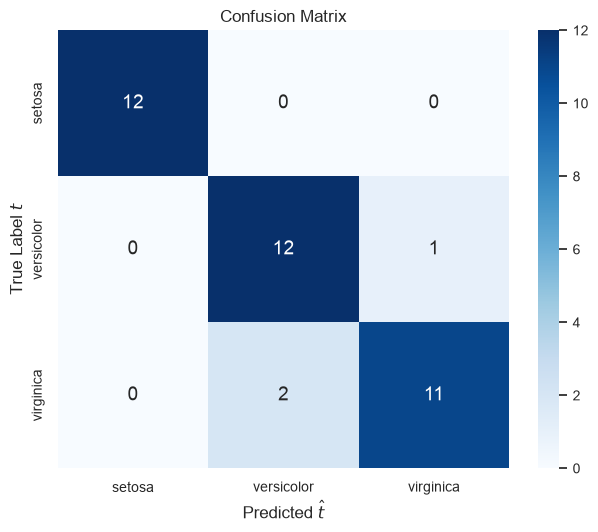

In [8]:
hp.plot_confusion_matrix(mt.confusion_matrix(y_test, y_pred), labels=model.classes_)

### Applied Benchmark: Breast Cancer Recurrence

- Breast cancer data: 286 patients with 9 categorical features (age group, menopause, tumour size, …)
- the goal is to predict if a tumor might reappear (recurrence-events) or not (no-recurrence-events)

In [9]:
# Load breast cancer dataset
bc = pd.read_csv(hp.get_file("breast-cancer.csv"))
bc.head()


,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [10]:
bc.describe(include='all')      

,recurrence,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
count,286,286,286,286,286,286,286.000000,286,286,286
unique,2,6,3,11,7,3,NaN,2,6,2
top,no-recurrence-events,50-59,premeno,30-34,0-2,no,NaN,left,left_low,no
freq,201,96,150,60,213,222,NaN,152,110,218
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.048951,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.738217,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN


In [11]:
# Counting estimate of p(deg-malig | class): shares within each class
pd.crosstab(bc["deg-malig"], bc["recurrence"], normalize="columns").round(3)

recurrence,no-recurrence-events,recurrence-events
deg-malig,,
1,0.294,0.141
2,0.507,0.329
3,0.199,0.529


### Categorical Features: Naive Bayes by Counting

- All features are qualitative, so $\hat{p}(x_i \mid \mathcal{C}_k)$ is the share of each value within the class (with Laplace smoothing): `CategoricalNB`.
- Encode the values as integer codes (`OrdinalEncoder`); the list of possible values of each feature comes from the data description, so rare values missing from a training fold do not break the model. Missing values (`?`) are imputed with the most frequent value.
- Compare by repeated stratified $5$-fold CV: baselines, `GaussianNB` on one-hot dummies (treats each 0/1 column as Gaussian, which is wrong for counts), `CategoricalNB`, and two ways to counter the class imbalance: equal priors and random oversampling of the minority class.

In [12]:
t_bc = (bc.recurrence == "recurrence-events").astype(int).to_numpy()            # 1 = recurrence
X_bc = bc.drop(columns="recurrence").replace("?", np.nan)
levels = [sorted(X_bc[column].dropna().unique(), key=str) for column in X_bc.columns]   # possible values per feature
n_levels = [len(values) for values in levels]

impute = SimpleImputer(strategy="most_frequent")
models = {
    "always 'no recurrence'": DummyClassifier(strategy="most_frequent"),
    "always 'recurrence'": DummyClassifier(strategy="constant", constant=1),
    "GaussianNB on one-hot": make_pipeline(impute, OneHotEncoder(categories=levels, sparse_output=False), GaussianNB()),
    "CategoricalNB": make_pipeline(impute, OrdinalEncoder(categories=levels), CategoricalNB(min_categories=n_levels)),
    "CategoricalNB, equal priors": make_pipeline(impute, OrdinalEncoder(categories=levels), CategoricalNB(min_categories=n_levels, class_prior=[0.5, 0.5])),
    "CategoricalNB + oversampling": make_imblearn_pipeline(impute, OrdinalEncoder(categories=levels), RandomOverSampler(random_state=42),
                                                           CategoricalNB(min_categories=n_levels)),
}
folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=1)
rows = []
for name, model in models.items():
    scores = cross_validate(model, X_bc, t_bc, cv=folds, scoring=["accuracy", "balanced_accuracy", "f1"])
    rows.append({"model": name, "accuracy": scores["test_accuracy"].mean(), "± sd": scores["test_accuracy"].std(),
                 "balanced accuracy": scores["test_balanced_accuracy"].mean(), "F1 (recurrence)": scores["test_f1"].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                       model  accuracy  ± sd  balanced accuracy  F1 (recurrence)
      always 'no recurrence'     0.703 0.002              0.500            0.000
         always 'recurrence'     0.297 0.002              0.500            0.458
       GaussianNB on one-hot     0.444 0.094              0.570            0.486
               CategoricalNB     0.731 0.046              0.651            0.498
 CategoricalNB, equal priors     0.693 0.045              0.665            0.533
CategoricalNB + oversampling     0.692 0.048              0.660            0.528


> 📝 **Note:** Random oversampling copies minority-class rows until both classes are equally frequent. For naive Bayes this mainly changes the estimated priors $\hat{p}(\mathcal{C}_k)$ to $0.5$, which is why "equal priors" behaves almost the same. Either way the model trades accuracy for catching more recurrences.

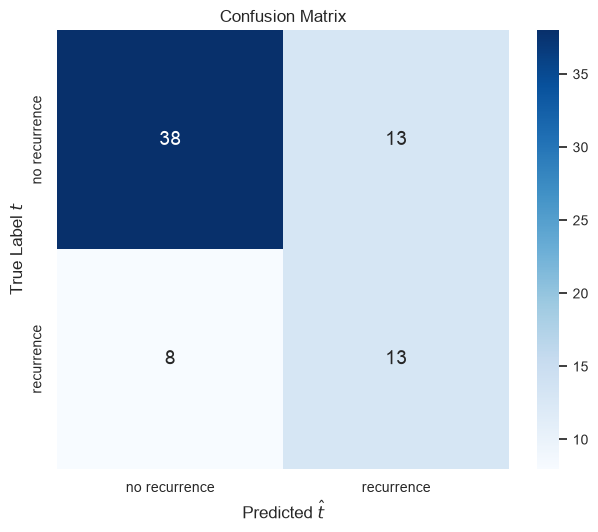

In [13]:
# One held-out evaluation of the oversampling variant
X_train, X_test, t_train, t_test = train_test_split(X_bc, t_bc, test_size=0.25, random_state=1, stratify=t_bc)
final_model = models["CategoricalNB + oversampling"].fit(X_train, t_train)
hp.plot_confusion_matrix(mt.confusion_matrix(t_test, final_model.predict(X_test)), labels=["no recurrence", "recurrence"])

## 5. Algorithm Selection Card: Naive Bayes

| Dimension | Assessment & Practical Guidance |
| :--- | :--- |
| **Best Suited For** | High-dimensional text classification (spam detection, sentiment), categorical tabular data, and lightning-fast baseline models with small-to-moderate training data. |
| **Key Hyperparameters** | • Variant Choice: `GaussianNB` (continuous features), `CategoricalNB` (categorical features, by counting), `MultinomialNB` (word counts); never `GaussianNB` on one-hot dummies.<br>• Smoothing Parameter $\alpha$ (Laplace/Lidstone smoothing) to prevent zero-frequency collapse.<br>• Class Priors (`priors` / `class_prior`); setting them equal has much the same effect as oversampling. |
| **Interpretability vs. Capacity** | **High Interpretability / Low-to-Moderate Capacity**: Transparent probabilistic feature likelihoods; cannot model non-linear feature interactions due to strict independence assumptions. |
| **Critical Pitfalls** | • **Zero Frequency**: Unseen feature-class pairs yield zero probability without Laplace smoothing $\alpha > 0$.<br>• **Correlated Features**: Correlated predictors are counted multiple times, over-confidently skewing posterior probabilities toward 0 or 1. |

> 💡 **Key Takeaway:** Naive Bayes pairs Bayes' theorem with feature conditional independence. It is computationally instantaneous, highly resistant to overfitting on small data, and a vital practical baseline.